### NASA IMS Bearing Degradation Analysis

This file is to examine whether the IMS data can be examined by Python, while also analyse the dataset (entire lifespan of Bearing 1 in Test 2).

In [2]:
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from predictive_maintenance.features import extract_time_features

In [3]:
# Define the data path
cwd = Path.cwd()

if (cwd / "data").exists():
    project_root = cwd
elif (cwd.parent / "data").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Could not find project data folder")

DATA_DIRECTORY = project_root / "data" / "ims" / "raw" / "2nd_test"

print(DATA_DIRECTORY)

c:\Users\User\Documents\Projects\predictive-maintenance-system\data\ims\raw\2nd_test


In [4]:
# Pre-processing (Timestamp is important for predictive maintenance)
# Read the recordings in chronological order
recordings = []
for file_path in DATA_DIRECTORY.iterdir():
    if not file_path.is_file():
        continue
    try:
        timestamp = datetime.strptime(file_path.name, "%Y.%m.%d.%H.%M.%S")
    except ValueError:
        continue
    recordings.append((timestamp, file_path))

# Sort only the timestamp in chronological order, ignore the file_path
recordings.sort(key=lambda item: item[0])

print("Total recordings:", len(recordings))
if not recordings:
    raise ValueError("No IMS recordings found")

print("First:", recordings[0][0])
print("Last:", recordings[-1][0])

Total recordings: 984
First: 2004-02-12 10:32:39
Last: 2004-02-19 06:22:39


In [5]:
# Verify one snapshot
first_file = recordings[0][1]
data = np.loadtxt(first_file)

print("Shape:", data.shape)

# Choose bearing 1 for this experiment since it is the documented failed bearing
bearing_1 = data[:, 0]
print("Bearing 1 samples:", len(bearing_1))

features = extract_time_features(bearing_1)
print("RMS:", features["rms"])
print("Kurtosis", features["kurtosis"])
print("Crest factor", features["crest_factor"])

Shape: (20480, 4)
Bearing 1 samples: 20480
RMS: 0.07417899856512623
Kurtosis 3.6292092021170044
Crest factor 6.120330670161392


In [6]:
# Extract features from all 984 recordings
rows = []

for index, (timestamp, file_path) in enumerate(recordings, start=1):
    # Read only the first column (Channel/Bearing 1)
    signal = np.loadtxt(file_path, usecols=(0,))

    samples = 20480
    if len(signal) != samples:
        raise ValueError(f"Unexpected sample count: {file_path.name}")
    if not np.all(np.isfinite(signal)):
        raise ValueError(f"Invalid signal values: {file_path.name}")

    features = extract_time_features(signal)

    rows.append({
        "timestamp": timestamp,
        "filename": file_path.name,
        "rms": features["rms"],
        "kurtosis": features["kurtosis"],
        "crest_factor": features["crest_factor"]
    })

    # Prints every 100 processed files (progress logging)
    if index % 100 == 0:
        print(f"Processed {index}/{len(recordings)}")

Processed 100/984
Processed 200/984
Processed 300/984
Processed 400/984
Processed 500/984
Processed 600/984
Processed 700/984
Processed 800/984
Processed 900/984


In [7]:
# Create the dataset
df = pd.DataFrame(rows)

df = df.sort_values("timestamp").reset_index(drop=True)

# Calculate the time passed since the first recordings in hours
df["elapsed_hours"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds() / 3600

print(df.head())
print(df.describe())

            timestamp             filename       rms  kurtosis  crest_factor  \
0 2004-02-12 10:32:39  2004.02.12.10.32.39  0.074179  3.629209      6.120331   
1 2004-02-12 10:42:39  2004.02.12.10.42.39  0.075382  3.648742      5.147086   
2 2004-02-12 10:52:39  2004.02.12.10.52.39  0.076230  3.513894      6.598472   
3 2004-02-12 11:02:39  2004.02.12.11.02.39  0.078724  4.158529      7.723217   
4 2004-02-12 11:12:39  2004.02.12.11.12.39  0.078474  3.603617      4.982524   

   elapsed_hours  
0       0.000000  
1       0.166667  
2       0.333333  
3       0.500000  
4       0.666667  
                 timestamp         rms    kurtosis  crest_factor  \
count                  984  984.000000  984.000000    984.000000   
mean   2004-02-15 20:27:39    0.106111    3.827633      5.173870   
min    2004-02-12 10:32:39    0.001533    1.390126      2.377543   
25%    2004-02-14 03:30:09    0.077137    3.394137      4.816583   
50%    2004-02-15 20:27:39    0.078778    3.485199      5.097702 

In [8]:
# Save results to CSV
OUTPUT_DIRECTORY = project_root / "runtime" / "ims_features"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIRECTORY / "test2_bearing1_features.csv"
df.to_csv(output_file, index=False)

print("Saved:", output_file)

Saved: c:\Users\User\Documents\Projects\predictive-maintenance-system\runtime\ims_features\test2_bearing1_features.csv


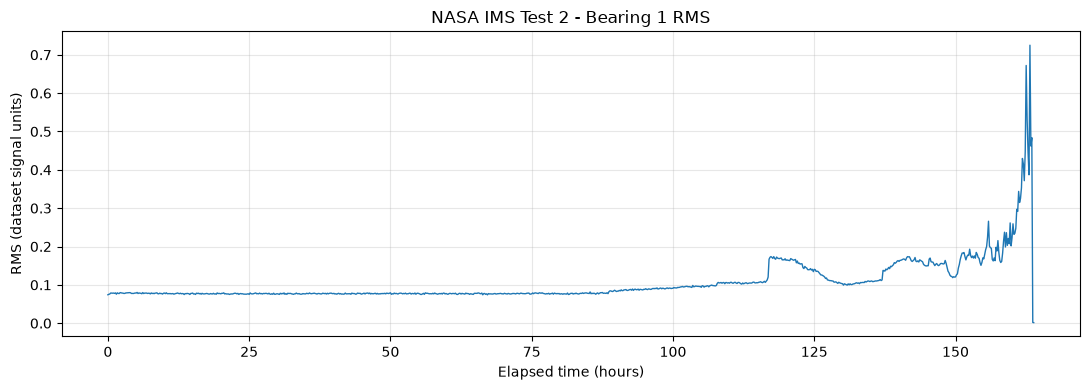

In [18]:
# Plot RMS trend
plt.figure(figsize=(11, 4))
plt.plot(df["elapsed_hours"], df["rms"], linewidth=1)

plt.xlabel("Elapsed time (hours)")
plt.ylabel("RMS (dataset signal units)")
plt.title("NASA IMS Test 2 - Bearing 1 RMS")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

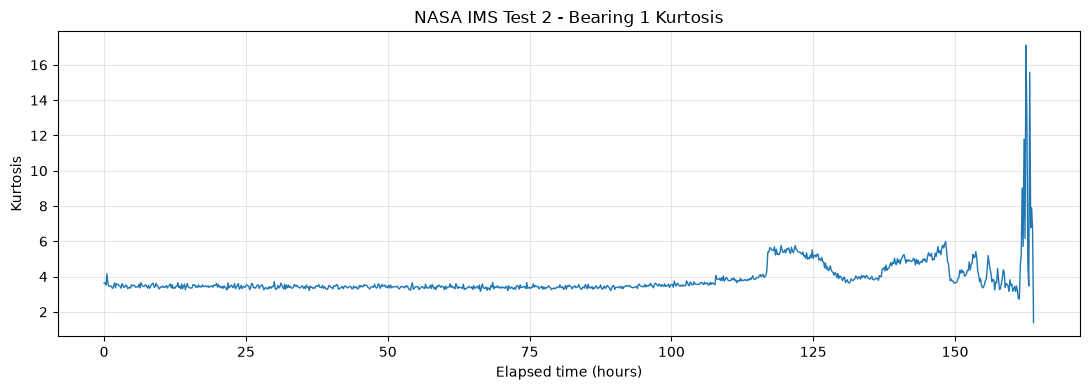

In [19]:
# Plot Kurtosis trend
plt.figure(figsize=(11, 4))
plt.plot(df["elapsed_hours"], df["kurtosis"], linewidth=1)

plt.xlabel("Elapsed time (hours)")
plt.ylabel("Kurtosis")
plt.title("NASA IMS Test 2 - Bearing 1 Kurtosis")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

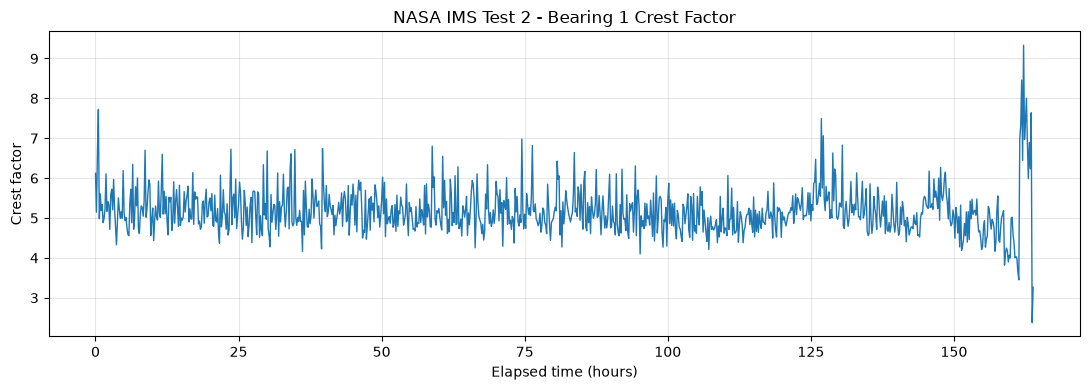

In [20]:
# Plot crest factor trend
plt.figure(figsize=(11, 4))
plt.plot(df["elapsed_hours"], df["crest_factor"], linewidth=1)

plt.xlabel("Elapsed time (hours)")
plt.ylabel("Crest factor")
plt.title("NASA IMS Test 2 - Bearing 1 Crest Factor")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
# Compare early and late measurements (first and last 10% rows)
n = max(1, len(df) // 10)

feature_columns = ["rms", "kurtosis", "crest_factor"]

early = df.iloc[:n]
late = df.iloc[-n:]

# Use median instead mean to prevent random sensor spikes or noise 
comparison = pd.DataFrame({
    "Early 10% median": early[feature_columns].median(),
    "Late 10% median": late[feature_columns].median()
})

comparison["Ratio (late/early)"] = comparison["Late 10% median"] / comparison["Early 10% median"]
print(comparison)

              Early 10% median  Late 10% median  Ratio (late/early)
rms                   0.077680         0.179637            2.312515
kurtosis              3.448805         4.072402            1.180816
crest_factor          5.211782         4.947081            0.949211


In [23]:
# From the graph, it shows that the RMS, kurtosis, and crest factor of the final points drop almost to zero.
# Investigate the last 8 points
print(df.tail(8)[
    [
        "timestamp",
        "filename",
        "rms",
        "kurtosis",
        "crest_factor"
    ]].to_string(index=False)
)

          timestamp            filename      rms  kurtosis  crest_factor
2004-02-19 05:12:39 2004.02.19.05.12.39 0.530956 12.799146      8.004428
2004-02-19 05:22:39 2004.02.19.05.22.39 0.445918  4.624967      6.875700
2004-02-19 05:32:39 2004.02.19.05.32.39 0.386975  3.469265      5.987469
2004-02-19 05:42:39 2004.02.19.05.42.39 0.725001 15.581069      6.896538
2004-02-19 05:52:39 2004.02.19.05.52.39 0.462012  6.761183      6.235773
2004-02-19 06:02:39 2004.02.19.06.02.39 0.483835  7.893243      7.638962
2004-02-19 06:12:39 2004.02.19.06.12.39 0.002103  6.638694      2.377543
2004-02-19 06:22:39 2004.02.19.06.22.39 0.001533  1.390126      3.262149


In [24]:
# Inspect the last recording
last_signal = np.loadtxt(recordings[-1][1], usecols=(0,))

print("Min:", last_signal.min())
print("Max:", last_signal.max())
print("Std:", last_signal.std())
print("Zero samples:", np.count_nonzero(last_signal == 0))

Min: -0.005
Max: 0.002
Std: 0.0009995548103707943
Zero samples: 8541


### Initial Engineering Observations

NASA IMS Test 2, Bearing 1 was analyzed using RMS, kurtosis, and crest factor extracted from chronologically ordered vibration recordings.

RMS showed relatively stable behaviour during the early operating period, followed by increasing levels and stronger fluctuations toward the end of the experiment. The late-period median RMS was approximately 2.31 times the early-period median.

Kurtosis showed changes during the later stages but did not increase consistently. Crest factor showed substantial variability and a slightly lower late-period median.

These observations suggest that RMS is a promising initial feature for investigating bearing degradation using Statistical Process Control (SPC).

**Limitations:** The initial healthy period and degradation onset have not yet been established statistically. An unusual final measurement also requires investigation before formal SPC analysis.